In [1]:
from pathlib import Path 
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

UNI_FILE = "university_rankings_2023.csv"
STU_FILE = "students_performance.csv"

DATA = Path('data')
FIG = Path('figures')

In [2]:
uni = pd.read_csv(DATA / UNI_FILE)
stu = pd.read_csv(DATA / STU_FILE)

In [3]:
uni.head()

,University Rank,Name of University,Location,No of student,No of student per staff,International Student,Female:Male Ratio,OverAll Score,Teaching Score,Research Score,Citations Score,Industry Income Score,International Outlook Score
0,1,University of Oxford,United Kingdom,"20,965",10.6,42%,48 : 52,96.4,92.3,99.7,99.0,74.9,96.2
1,2,Harvard University,United States,"21,887",9.6,25%,50 : 50,95.2,94.8,99.0,99.3,49.5,80.5
2,3,University of Cambridge,United Kingdom,"20,185",11.3,39%,47 : 53,94.8,90.9,99.5,97.0,54.2,95.8
3,3,Stanford University,United States,"16,164",7.1,24%,46 : 54,94.8,94.2,96.7,99.8,65.0,79.8
4,5,Massachusetts Institute of Technology,United States,"11,415",8.2,33%,40 : 60,94.2,90.7,93.6,99.8,90.9,89.3


In [4]:
stu.head()

,STUDENT ID,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,COURSE ID,GRADE
0,STUDENT1,2,2,3,3,1,2,2,1,1,...,1,1,3,2,1,2,1,1,1,1
1,STUDENT2,2,2,3,3,1,2,2,1,1,...,1,1,3,2,3,2,2,3,1,1
2,STUDENT3,2,2,2,3,2,2,2,2,4,...,1,1,2,2,1,1,2,2,1,1
3,STUDENT4,1,1,1,3,1,2,1,2,1,...,1,2,3,2,2,1,3,2,1,1
4,STUDENT5,2,2,1,3,2,2,1,3,1,...,2,1,2,2,2,1,2,2,1,1


In [7]:
print("baris x kolom : ", uni.shape)
print("baris duplikat : ", int(uni.duplicated().sum()))
print("jumlah lokasi unik : ", uni['Location'].nunique())
print()

print("nilai kosong per kolom")
uni.isnull().sum()

baris x kolom :  (2341, 13)
baris duplikat :  29
jumlah lokasi unik :  116

nilai kosong per kolom


University Rank                  0
Name of University             108
Location                       294
No of student                  132
No of student per staff        133
International Student          132
Female:Male Ratio              213
OverAll Score                  542
Teaching Score                 542
Research Score                 542
Citations Score                542
Industry Income Score          542
International Outlook Score    542
dtype: int64

In [8]:
uni.info()

<class 'pandas.DataFrame'>
RangeIndex: 2341 entries, 0 to 2340
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   University Rank              2341 non-null   str    
 1   Name of University           2233 non-null   str    
 2   Location                     2047 non-null   str    
 3   No of student                2209 non-null   str    
 4   No of student per staff      2208 non-null   float64
 5   International Student        2209 non-null   str    
 6   Female:Male Ratio            2128 non-null   str    
 7   OverAll Score                1799 non-null   str    
 8   Teaching Score               1799 non-null   float64
 9   Research Score               1799 non-null   float64
 10  Citations Score              1799 non-null   float64
 11  Industry Income Score        1799 non-null   float64
 12  International Outlook Score  1799 non-null   float64
dtypes: float64(6), str(7)
memory 

In [10]:
stu.head()

,STUDENT ID,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,COURSE ID,GRADE
0,STUDENT1,2,2,3,3,1,2,2,1,1,...,1,1,3,2,1,2,1,1,1,1
1,STUDENT2,2,2,3,3,1,2,2,1,1,...,1,1,3,2,3,2,2,3,1,1
2,STUDENT3,2,2,2,3,2,2,2,2,4,...,1,1,2,2,1,1,2,2,1,1
3,STUDENT4,1,1,1,3,1,2,1,2,1,...,1,2,3,2,2,1,3,2,1,1
4,STUDENT5,2,2,1,3,2,2,1,3,1,...,2,1,2,2,2,1,2,2,1,1


In [11]:
kodebook = pd.DataFrame([
    ('1',  'Student Age', '1: 18-21, 2: 22-25, 3: above 26'),
    ('2',  'Sex', '1: female, 2: male'),
    ('3',  'Graduated high-school type', '1: private, 2: state, 3: other'),
    ('4',  'Scholarship type', '1: None, 2: 25%, 3: 50%, 4: 75%, 5: Full'),
    ('5',  'Additional work', '1: Yes, 2: No'),
    ('6',  'Regular artistic or sports activity', '1: Yes, 2: No'),
    ('7',  'Do you have a partner', '1: Yes, 2: No'),
    ('8',  'Total salary if available', '1: USD 135-200, 2: 201-270, 3: 271-340, 4: 341-410, 5: above 410'),
    ('9',  'Transportation to the university', '1: Bus, 2: Private car/taxi, 3: bicycle, 4: Other'),
    ('10', 'Accommodation type in Cyprus', '1: rental, 2: dormitory, 3: with family, 4: Other'),
    ('11', "Mothers' education", '1: primary school, 2: secondary school, 3: high school, 4: university, 5: MSc., 6: Ph.D.'),
    ('12', "Fathers' education", '1: primary school, 2: secondary school, 3: high school, 4: university, 5: MSc., 6: Ph.D.'),
    ('13', 'Number of sisters/brothers', '1: 1, 2: 2, 3: 3, 4: 4, 5: 5 or above'),
    ('14', 'Parental status', '1: married, 2: divorced, 3: died (one of them or both)'),
    ('15', "Mothers' occupation", '1: retired, 2: housewife, 3: government officer, 4: private sector employee, 5: self-employment, 6: other'),
    ('16', "Fathers' occupation", '1: retired, 2: government officer, 3: private sector employee, 4: self-employment, 5: other'),
    ('17', 'Weekly study hours', '1: None, 2: <5 hours, 3: 6-10 hours, 4: 11-20 hours, 5: more than 20 hours'),
    ('18', 'Reading frequency (non-scientific books/journals)', '1: None, 2: Sometimes, 3: Often'),
    ('19', 'Reading frequency (scientific books/journals)', '1: None, 2: Sometimes, 3: Often'),
    ('20', 'Attendance to seminars/conferences related to the department', '1: Yes, 2: No'),
    ('21', 'Impact of projects/activities on success', '1: positive, 2: negative, 3: neutral'),
    ('22', 'Attendance to classes', '1: always, 2: sometimes, 3: never'),
    ('23', 'Preparation to midterm exams 1', '1: alone, 2: with friends, 3: not applicable'),
    ('24', 'Preparation to midterm exams 2', '1: closest date to the exam, 2: regularly during the semester, 3: never'),
    ('25', 'Taking notes in classes', '1: never, 2: sometimes, 3: always'),
    ('26', 'Listening in classes', '1: never, 2: sometimes, 3: always'),
    ('27', 'Discussion improves my interest and success in the course', '1: never, 2: sometimes, 3: always'),
    ('28', 'Flip-classroom', '1: not useful, 2: useful, 3: not applicable'),
    ('29', 'Cumulative GPA in the last semester (/4.00)', '1: <2.00, 2: 2.00-2.49, 3: 2.50-2.99, 4: 3.00-3.49, 5: above 3.49'),
    ('30', 'Expected cumulative GPA at graduation (/4.00)', '1: <2.00, 2: 2.00-2.49, 3: 2.50-2.99, 4: 3.00-3.49, 5: above 3.49'),
    ('COURSE ID', 'Course ID', 'kode mata kuliah'),
    ('GRADE', 'OUTPUT Grade', '0: Fail, 1: DD, 2: DC, 3: CC, 4: CB, 5: BB, 6: BA, 7: AA'),
], columns =['kolom', 'pertanyaan', 'kode'])

pd.set_option('display.max_colwidth', None)
kodebook

,kolom,pertanyaan,kode
0,1,Student Age,"1: 18-21, 2: 22-25, 3: above 26"
1,2,Sex,"1: female, 2: male"
2,3,Graduated high-school type,"1: private, 2: state, 3: other"
3,4,Scholarship type,"1: None, 2: 25%, 3: 50%, 4: 75%, 5: Full"
4,5,Additional work,"1: Yes, 2: No"
5,6,Regular artistic or sports activity,"1: Yes, 2: No"
6,7,Do you have a partner,"1: Yes, 2: No"
7,8,Total salary if available,"1: USD 135-200, 2: 201-270, 3: 271-340, 4: 341-410, 5: above 410"
8,9,Transportation to the university,"1: Bus, 2: Private car/taxi, 3: bicycle, 4: Other"
9,10,Accommodation type in Cyprus,"1: rental, 2: dormitory, 3: with family, 4: Other"


In [12]:
pd.DataFrame({
    'dtype' : uni.dtypes.astype(str),
    'nilai_unik' : uni.nunique(),
    'contoh' : uni.iloc[0],
})

,dtype,nilai_unik,contoh
University Rank,str,162,1
Name of University,str,2233,University of Oxford
Location,str,116,United Kingdom
No of student,str,2136,"20,965"
No of student per staff,float64,420,10.6
International Student,str,79,42%
Female:Male Ratio,str,87,48 : 52
OverAll Score,str,160,96.4
Teaching Score,float64,437,92.3
Research Score,float64,477,99.7


In [ ]:
# data random 
np.random.seed(42)
y = np.random.normal(loc = 16, scale = 10, size = 10)
y.round(2)

array([20.97, 14.62, 22.48, 31.23, 13.66, 13.66, 31.79, 23.67, 11.31,
       21.43])

In [15]:
print("mean               : ", y.mean())
print("median             : ", np.median(y))
print("variance           : ", np.var(y,ddof = 1))
print("standard deviation : ", np.std(y, ddof = 1))
print("range              : ", np.ptp(y))
print("kuartil            : ", np.percentile(y, [25, 50, 75]))
print("IQR                : ", stats.iqr(y))

mean               :  20.48061111698756
median             :  21.19637098298599
variance           :  52.27410502368407
standard deviation :  7.2300833344909705
range              :  20.486872014423437
kuartil            :  [13.89831207 21.19637098 23.37498181]
IQR                :  9.476669743945362


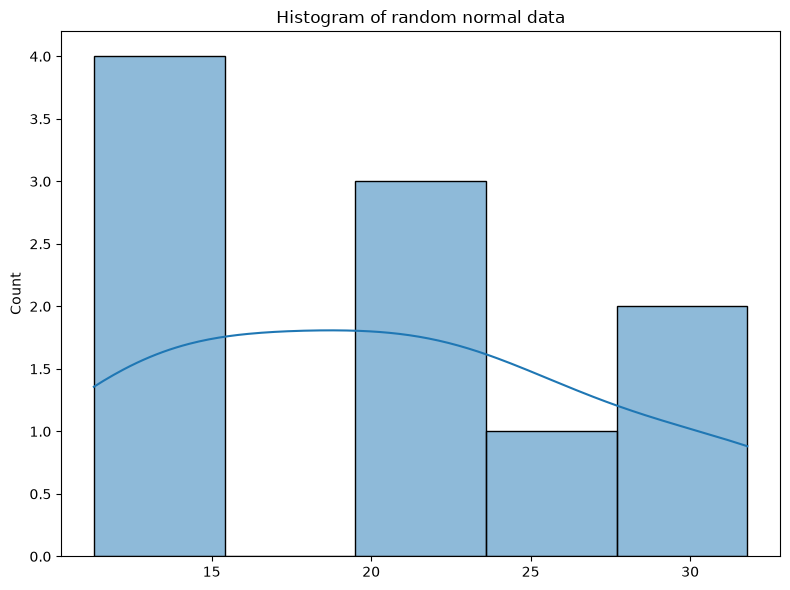

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(y, kde=True, ax=ax)
ax.set_title("Histogram of random normal data")
fig.tight_layout(); fig.savefig(FIG/ "histogram_random_normal.png")
plt.show()

In [19]:
kosong =uni.drop(columns = "University Rank").isna().all(axis=1)
print("baris yg sepenuhnya kosong : ", int(kosong.sum()))


baris yg sepenuhnya kosong :  30


In [20]:
df = uni[~kosong].copy()
print('duplikat setelah dibuang : ', int(df.duplicated().sum()))

duplikat setelah dibuang :  0


In [25]:
def titik_tengah(s):
    if pd.isna(s):
        return np.nan
    bagian = [float(x) for x in s.split('–')]
    return sum(bagian)/len(bagian)

df["overall_tengah"] = df["OverAll Score"].map(titik_tengah)
df['n_mahasiswa'] = pd.to_numeric(df["No of student"].str.replace(',',''), errors = "coerce")
df['intl_pct']=pd.to_numeric(df['International Student'].str.rstrip("%"), errors = "coerce")

rasio = df["Female:Male Ratio"].str.split(":",expand=True).apply(lambda k: pd.to_numeric(k.str.strip(), errors = "coerce"))
df['female_pct']=rasio[0]/(rasio[0]+rasio[1])*100

df[['OverAll Score', 'overall_tengah', 'No of student', 'n_mahasiswa',
    'International Student', 'intl_pct', 'Female:Male Ratio', 'female_pct']].head()

,OverAll Score,overall_tengah,No of student,n_mahasiswa,International Student,intl_pct,Female:Male Ratio,female_pct
0,96.4,96.4,"20,965",20965.0,42%,42.0,48 : 52,48.0
1,95.2,95.2,"21,887",21887.0,25%,25.0,50 : 50,50.0
2,94.8,94.8,"20,185",20185.0,39%,39.0,47 : 53,47.0
3,94.8,94.8,"16,164",16164.0,24%,24.0,46 : 54,46.0
4,94.2,94.2,"11,415",11415.0,33%,33.0,40 : 60,40.0


In [26]:
uni.columns

Index(['University Rank', 'Name of University', 'Location', 'No of student',
       'No of student per staff', 'International Student', 'Female:Male Ratio',
       'OverAll Score', 'Teaching Score', 'Research Score', 'Citations Score',
       'Industry Income Score', 'International Outlook Score'],
      dtype='str')

In [27]:
SCORE_COLS = ['OverAll Score', 'Teaching Score', 'Research Score', 'Citations Score',
       'Industry Income Score', 'International Outlook Score']
EXTRA_COLS = ["overall_tengah", "n_mahasiswa", "intl_pct", "female_pct"]
LOC = "Location"
IND = "Industry Income Score"

scored = df.dropna(subset=SCORE_COLS)
print("baris dengan skor lengkap : ", len(scored))

baris dengan skor lengkap :  1799


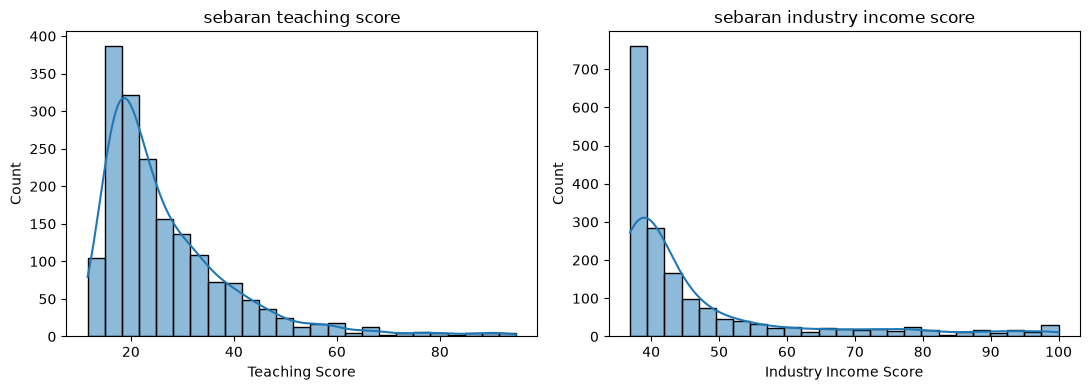

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(scored['Teaching Score'], bins= 25, kde=True, ax=axes[0])
axes[0].set_title("sebaran teaching score")
sns.histplot(scored[IND], bins= 25, kde=True, ax=axes[1])
axes[1].set_title("sebaran industry income score")
fig.tight_layout(); fig.savefig(FIG/ "hist_scores.png", dpi=150)
plt.show()

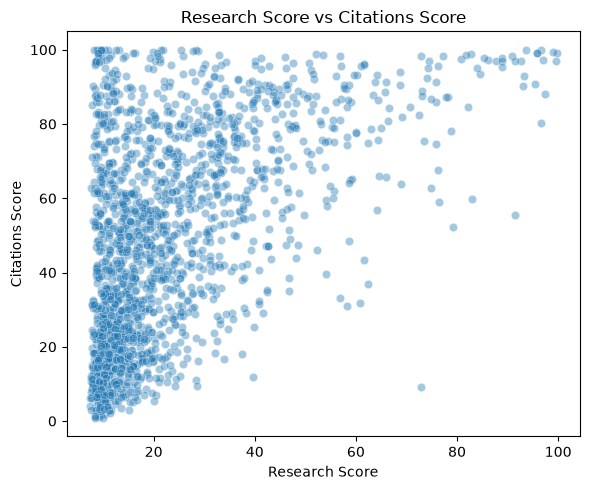

In [35]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=scored, x='Research Score', y='Citations Score', alpha=0.4, ax=ax)
ax.set_title("Research Score vs Citations Score")
fig.tight_layout(); fig.savefig(FIG/ "scatter_research_citations.png", dpi=150)
plt.show()